# Lucrarea de laborator 2

## Procesarea datelor în Databricks, clasificarea recenziilor și vizualizarea în Power BI

### Obiectivul lucrării

Lucrarea continuă procesarea Yelp Open Dataset realizată în laboratorul 1. Se reutilizează datele curățate pentru pregătirea unui subset local de aproximativ 100 MB, care va fi transferat în Databricks.

Fluxul de lucru include:
1. Pregătirea subsetului local.
2. Încărcarea și organizarea datelor în Databricks.
3. Antrenarea și evaluarea unui model de clasificare cu Spark MLlib.
4. Salvarea predicțiilor și demonstrarea mecanismelor de fiabilitate.
5. Construirea unui raport interactiv în Power BI.

### Problema predictivă

Pe baza textului unei recenzii se urmărește identificarea recenziilor cu rating scăzut:
- `label = 1`: rating de 1–2 stele;
- `label = 0`: rating de 3–5 stele.

Clasa `0` înseamnă „fără rating scăzut”, nu neapărat sentiment pozitiv.

Textul reprezintă intrarea modelului. Ratingul este utilizat pentru construirea etichetei de referință și nu va fi inclus ca variabilă predictivă.

## 1. Pregătirea subsetului local

### 1.1. Sursa datelor

Se utilizează tabelul Delta rezultat din etapa de prelucrare a laboratorului 1:

`laborator_1/data/processed_delta`

Tabelul conține recenziile și contextul asociat afacerilor. Schema sa păstrează informațiile necesare atât clasificării, cât și raportului Power BI:

| Coloane | Utilizare |
|---|---|
| `review_id` | Identificarea recenziei și verificarea unicității |
| `business_id` | Identificarea afacerii |
| `text` | Intrarea modelului de clasificare |
| `stars` | Construirea etichetei |
| `date`, `year`, `month` | Analiza temporală |
| `name`, `city`, `state`, `main_category` | Contextul afacerii și filtrele raportului |
| `text_length`, `useful`, `funny`, `cool`, `total_votes` | Atribute disponibile pentru analiza descriptivă |

Datele despre afaceri sunt deja incluse în sursă, astfel încât nu este necesară o asociere suplimentară cu `dim_business`.

Fluxul de curățare din laboratorul 1 nu este repetat. În această etapă se verifică datele de intrare, se pregătește o selecție reproductibilă și se exportă subsetul în format Parquet.

Ținta de aproximativ 100 MB se referă la dimensiunea efectivă a fișierelor Parquet exportate.

### 1.2. Inițializarea mediului local

Pregătirea subsetului se execută în mediul local utilizat pentru laboratorul 1.

Se reutilizează funcția `get_spark` din modulul `src.lab_common`, cu integrarea Kafka dezactivată.

Căile sursei și destinației sunt definite explicit. Tabelul Delta din laboratorul 1 este utilizat numai pentru citire; subsetul va fi salvat separat, în directorul laboratorului 2.

In [0]:
from pathlib import Path
import sys

from pyspark.sql import functions as F

# Configurația locală a repository-ului.
REPO_ROOT = Path("/home/ivan/tmp/new/big_data")

LAB1_ROOT = REPO_ROOT / "laborator_1"
SOURCE_PATH = LAB1_ROOT / "data" / "processed_delta"
SUBSET_PATH = REPO_ROOT / "laborator_2" / "data" / "yelp_subset"

if not (SOURCE_PATH / "_delta_log").is_dir():
    raise FileNotFoundError(
        f"Tabelul Delta nu este disponibil la calea: {SOURCE_PATH}"
    )

if str(LAB1_ROOT) not in sys.path:
    sys.path.insert(0, str(LAB1_ROOT))

from src.lab_common import get_spark

spark = get_spark(app="yelp-lab2-subset", kafka=False)

reviews_clean = spark.read.format("delta").load(str(SOURCE_PATH))

print("Spark:", spark.version)
print("Sursă:", SOURCE_PATH)
print("Destinația planificată:", SUBSET_PATH)

:: loading settings :: url = jar:file:/home/ivan/.mamba/envs/Playground/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/ivan/.ivy2.5.2/cache
The jars for the packages stored in: /home/ivan/.ivy2.5.2/jars
io.delta#delta-spark_4.1_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-b850eb39-29e3-4033-a178-7c16fe3070df;1.0
	confs: [default]
	found io.delta#delta-spark_4.1_2.13;4.4.0 in central
	found io.delta#delta-storage;4.4.0 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-

Spark: 4.1.1
Sursă: /home/ivan/tmp/new/big_data/laborator_1/data/processed_delta
Destinația planificată: /home/ivan/tmp/new/big_data/laborator_2/data/yelp_subset


### 1.3. Verificarea datelor de intrare

Înaintea selecției se execută verificări de control asupra sursei:
- existența coloanelor necesare;
- completitudinea și unicitatea identificatorilor recenziilor;
- prezența unui text nevid;
- apartenența ratingului la valorile 1, 2, 3, 4 sau 5;
- prezența datei și concordanța acesteia cu anul;
- disponibilitatea contextului utilizat în dashboard.

Aceste verificări nu modifică tabelul sursă. Eventualele probleme vor fi analizate înainte de stabilirea regulilor de selecție.

Agregările sunt executate pe întregul tabel și presupun citirea datelor, nu doar consultarea metadatelor.

In [0]:
required_columns = [
    "review_id",
    "business_id",
    "text",
    "stars",
    "date",
    "year",
    "month",
    "name",
    "city",
    "state",
    "main_category",
    "text_length",
    "useful",
    "funny",
    "cool",
    "total_votes",
]

missing_columns = sorted(set(required_columns) - set(reviews_clean.columns))

if missing_columns:
    raise ValueError(f"Coloane necesare lipsă: {missing_columns}")


def is_missing_text(column_name):
    column = F.col(column_name)
    return column.isNull() | (F.length(F.trim(column)) == 0)


def count_if(condition, alias):
    return F.count(F.when(condition, F.lit(1))).alias(alias)


invalid_id = is_missing_text("review_id")
invalid_text = is_missing_text("text")

invalid_stars = (
    F.col("stars").isNull()
    | F.isnan("stars")
    | ~F.col("stars").isin(1.0, 2.0, 3.0, 4.0, 5.0)
)

invalid_date = F.col("date").isNull()

invalid_year = (
    F.col("year").isNull()
    | (F.col("year") != F.year("date"))
)

quality = reviews_clean.agg(
    F.count("*").alias("n_rows"),
    F.countDistinct("review_id").alias("n_distinct_review_ids"),
    count_if(invalid_id, "invalid_review_id"),
    count_if(invalid_text, "invalid_text"),
    count_if(invalid_stars, "invalid_stars"),
    count_if(invalid_date, "invalid_date"),
    count_if(invalid_year, "invalid_year"),
    count_if(is_missing_text("business_id"), "missing_business_id"),
    count_if(is_missing_text("name"), "missing_business_name"),
    count_if(is_missing_text("city"), "missing_city"),
    count_if(is_missing_text("state"), "missing_state"),
    count_if(is_missing_text("main_category"), "missing_main_category"),
    F.min("date").alias("min_date"),
    F.max("date").alias("max_date"),
    F.round(F.avg(F.length("text")), 1).alias("avg_text_characters"),
).first().asDict()

for key, value in quality.items():
    print(f"{key}: {value}")

unique_valid_ids = (
    quality["invalid_review_id"] == 0
    and quality["n_rows"] == quality["n_distinct_review_ids"]
)

print("\nIdentificatori review_id unici și nenuli:", unique_valid_ids)

26/10/27 09:18:59 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


n_rows: 6958470
n_distinct_review_ids: 6958470
invalid_review_id: 0
invalid_text: 0
invalid_stars: 0
invalid_date: 0
invalid_year: 0
missing_business_id: 0
missing_business_name: 0
missing_city: 0
missing_state: 0
missing_main_category: 0
min_date: 2005-02-16 03:23:22
max_date: 2021-12-31 23:59:26
avg_text_characters: 568.0

Identificatori review_id unici și nenuli: True


### 1.4. Distribuția temporală și distribuția claselor

Se examinează numărul recenziilor pe ani și distribuția ratingurilor pentru a caracteriza sursa înainte de eșantionare.

Pentru analiza claselor se construiește explicit eticheta `label` din coloana `stars`:
- `1` pentru recenziile cu 1–2 stele;
- `0` pentru recenziile cu 3–5 stele.

Coloana existentă `is_positive` nu este reutilizată, deoarece definiția ei nu este presupusă identică problemei de clasificare din această lucrare.

Distribuția pe ani permite evaluarea acoperirii temporale, iar proporția clasei cu rating scăzut evidențiază un eventual dezechilibru între clase.

Analiza etichetelor include numai ratingurile valide. Tabelul sursă nu este modificat.

In [0]:
reviews_distribution = (
    reviews_clean
    .filter(~invalid_stars)
    .withColumn(
        "label",
        F.when(F.col("stars") <= 2.0, F.lit(1)).otherwise(F.lit(0)),
    )
)

year_distribution = (
    reviews_distribution
    .groupBy("year")
    .agg(
        F.count("*").alias("n_reviews"),
        F.sum("label").alias("n_low_rating"),
        F.round(
            100.0 * F.avg("label"), 2
        ).alias("low_rating_pct"),
    )
    .orderBy("year")
)

print("Distribuția pe ani — ratinguri valide:")
year_distribution.show(100, truncate=False)

print("Distribuția pe rating — sursa completă:")
(
    reviews_clean
    .groupBy("stars")
    .count()
    .orderBy("stars")
    .show(truncate=False)
)

print("Distribuția claselor — ratinguri valide:")
(
    reviews_distribution
    .groupBy("label")
    .count()
    .orderBy("label")
    .show(truncate=False)
)

Distribuția pe ani — ratinguri valide:
+----+---------+------------+--------------+
|year|n_reviews|n_low_rating|low_rating_pct|
+----+---------+------------+--------------+
|2005|854      |84          |9.84          |
|2006|3853     |351         |9.11          |
|2007|15363    |1855        |12.07         |
|2008|48224    |6338        |13.14         |
|2009|74386    |12623       |16.97         |
|2010|138584   |23830       |17.2          |
|2011|230809   |42823       |18.55         |
|2012|286569   |58346       |20.36         |
|2013|383942   |81416       |21.21         |
|2014|522271   |113799      |21.79         |
|2015|688412   |154894      |22.5          |
|2016|758869   |173982      |22.93         |
|2017|820033   |189115      |23.06         |
|2018|906346   |214443      |23.66         |
|2019|907245   |221958      |24.47         |
|2020|554548   |140400      |25.32         |
|2021|618162   |168934      |27.33         |
+----+---------+------------+--------------+

Distribuția pe 

### 1.5. Rezultatele verificării sursei

Tabelul sursă conține **6.958.470 de recenzii**, fiecare având un identificator `review_id` unic și nenul.

Controalele executate nu au identificat:
- texte nule sau vide;
- ratinguri lipsă sau în afara valorilor permise;
- date lipsă sau neconcordanțe între dată și an;
- valori lipsă în câmpurile de context verificate: identificatorul și denumirea afacerii, orașul, statul și categoria principală.

Recenziile acoperă intervalul **16 februarie 2005 – 31 decembrie 2021**, iar lungimea medie a textului este de **568 de caractere**.

Distribuția claselor este dezechilibrată:
- clasa `0`, fără rating scăzut: **5.353.279 de recenzii**;
- clasa `1`, cu rating scăzut: **1.605.191 de recenzii**.

Proporția recenziilor cu rating scăzut diferă între ani: de exemplu, este de 9,84% în 2005 și de 27,33% în 2021. Această variație justifică păstrarea dimensiunii temporale pentru analiza ulterioară.

Rezultatele permit continuarea pregătirii subsetului fără aplicarea unor corecții suplimentare pentru problemele verificate. Ele nu demonstrează absența tuturor problemelor semantice posibile, precum variațiile de scriere ale orașelor.

### 1.6. Selecția reproductibilă a recenziilor

Subsetul este construit printr-o selecție deterministă bazată pe hash-ul identificatorului `review_id`.

Fiecărei recenzii îi este atribuit un bucket între 0 și 9.999. Sunt păstrate recenziile al căror bucket este mai mic decât pragul configurat.

Metoda oferă:
- repetabilitatea selecției pentru aceeași sursă și aceeași configurație;
- independență față de ordinea fizică a rândurilor;
- posibilitatea de a ajusta proporția fără schimbarea metodei;
- subseturi imbricate: creșterea pragului păstrează recenziile deja selectate.

Selecția este aplicată întregului interval temporal, fără echilibrarea artificială a claselor. Se urmărește păstrarea aproximativă a distribuțiilor sursei, nu un număr identic de recenzii pentru fiecare an sau clasă.

Prima selecție utilizează un prag de 500 din 10.000, corespunzător unei proporții nominale de 5%. Numărul efectiv de rânduri și dimensiunea fișierelor sunt măsurate după export.

Coloanele exportate includ textul, eticheta și contextul necesar analizei. Prezența ratingului și a contextului în subset nu înseamnă că acestea vor fi utilizate ca intrări ale modelului: pentru clasificarea propusă, intrarea predictivă rămâne textul.

In [0]:
# Parametrii selecției.
HASH_BUCKETS = 10_000
SELECTION_THRESHOLD = 500  # Proporție nominală: 5%.

assert 1 <= SELECTION_THRESHOLD <= HASH_BUCKETS

export_columns = [
    "review_id",
    "business_id",
    "text",
    "stars",
    "date",
    "year",
    "month",
    "name",
    "city",
    "state",
    "main_category",
    "label",
]

reviews_labeled = reviews_clean.withColumn(
    "label",
    F.when(F.col("stars") <= 2.0, F.lit(1.0)).otherwise(F.lit(0.0)),
)

subset = (
    reviews_labeled
    .withColumn(
        "_selection_bucket",
        F.pmod(F.xxhash64("review_id"), F.lit(HASH_BUCKETS)),
    )
    .filter(F.col("_selection_bucket") < SELECTION_THRESHOLD)
    .select(*export_columns)
)

print(
    "Proporție nominală selectată:",
    f"{100 * SELECTION_THRESHOLD / HASH_BUCKETS:.2f}%",
)

subset.printSchema()

Proporție nominală selectată: 5.00%
root
 |-- review_id: string (nullable = true)
 |-- business_id: string (nullable = true)
 |-- text: string (nullable = true)
 |-- stars: double (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- state: string (nullable = true)
 |-- main_category: string (nullable = true)
 |-- label: double (nullable = false)



### 1.7. Exportul local în Parquet

Subsetul este salvat în directorul:

`laborator_2/data/yelp_subset`

Se utilizează formatul Parquet cu compresie Snappy. Pentru acest subset nu se aplică partiționarea pe ani, pentru a evita fragmentarea în numeroase fișiere mici, în special pentru anii cu puține recenzii.

Exportul este distribuit în patru partiții de execuție. Numărul de partiții nu garantează o anumită dimensiune a fișierelor.

Modul `overwrite` permite regenerarea exportului la ajustarea pragului de selecție. Acesta înlocuiește exclusiv conținutul destinației subsetului și nu modifică tabelul sursă.

După export se măsoară:
- dimensiunea cumulată a fișierelor Parquet;
- dimensiunea totală a directorului, inclusiv fișierele auxiliare;
- numărul de recenzii exportate;
- distribuția claselor și acoperirea temporală.

În această lucrare, ținta de 100 MB este interpretată în unități zecimale: 100.000.000 de octeți. Dimensiunea în MiB este afișată separat.

Dimensiunea efectivă depinde de lungimea textelor, coloanele păstrate și compresie; de aceea pragul de selecție este calibrat pe baza exportului măsurat.

In [0]:
TARGET_BYTES = 100_000_000
EXPORT_PARTITIONS = 4

# Protecție împotriva suprascrierii accidentale a altei destinații.
expected_subset_path = (
    REPO_ROOT / "laborator_2" / "data" / "yelp_subset"
).resolve()

assert SUBSET_PATH.resolve() == expected_subset_path
assert SOURCE_PATH.resolve() != SUBSET_PATH.resolve()

(
    subset
    .repartition(EXPORT_PARTITIONS)
    .write
    .mode("overwrite")
    .option("compression", "snappy")
    .parquet(str(SUBSET_PATH))
)

# Verificăm datele citite din export, nu doar DataFrame-ul de dinaintea scrierii.
exported_subset = spark.read.parquet(str(SUBSET_PATH))

parquet_files = sorted(SUBSET_PATH.rglob("*.parquet"))
all_files = [
    path for path in SUBSET_PATH.rglob("*")
    if path.is_file()
]

parquet_bytes = sum(path.stat().st_size for path in parquet_files)
directory_bytes = sum(path.stat().st_size for path in all_files)

if parquet_bytes == 0:
    raise RuntimeError("Exportul nu conține fișiere Parquet cu date.")

export_summary = exported_subset.agg(
    F.count("*").alias("n_reviews"),
    F.countDistinct("review_id").alias("n_distinct_review_ids"),
    F.min("date").alias("min_date"),
    F.max("date").alias("max_date"),
).first().asDict()

print("Destinație:", SUBSET_PATH)
print("Fișiere Parquet:", len(parquet_files))
print(f"Dimensiune Parquet: {parquet_bytes / 1_000_000:.2f} MB")
print(f"Dimensiune Parquet: {parquet_bytes / (1024 ** 2):.2f} MiB")
print(f"Dimensiune totală director: {directory_bytes / 1_000_000:.2f} MB")
print(
    "Proporție efectivă din rândurile sursei:",
    f"{100 * export_summary['n_reviews'] / quality['n_rows']:.2f}%",
)

for key, value in export_summary.items():
    print(f"{key}: {value}")

print("\nDistribuția claselor în export:")
(
    exported_subset
    .groupBy("label")
    .agg(
        F.count("*").alias("n_reviews"),
    )
    .withColumn(
        "percentage",
        F.round(
            100.0 * F.col("n_reviews") / F.lit(export_summary["n_reviews"]),
            2,
        ),
    )
    .orderBy("label")
    .show(truncate=False)
)

print("Distribuția temporală în export:")
(
    exported_subset
    .groupBy("year")
    .count()
    .orderBy("year")
    .show(100, truncate=False)
)

# Estimare pentru următoarea rulare, fără reexport automat.
suggested_threshold = max(
    1,
    min(
        HASH_BUCKETS,
        round(SELECTION_THRESHOLD * TARGET_BYTES / parquet_bytes),
    ),
)

print(
    "\nPrag estimat pentru apropierea de 100 MB:",
    suggested_threshold,
)
print(
    "Estimarea presupune o relație aproximativ proporțională "
    "între prag și dimensiunea exportului."
)

Destinație: /home/ivan/tmp/new/big_data/laborator_2/data/yelp_subset
Fișiere Parquet: 4
Dimensiune Parquet: 148.78 MB
Dimensiune Parquet: 141.89 MiB
Dimensiune totală director: 149.94 MB
Proporție efectivă din rândurile sursei: 5.00%
n_reviews: 347694
n_distinct_review_ids: 347694
min_date: 2005-03-01 16:59:37
max_date: 2021-12-31 23:50:20

Distribuția claselor în export:
+-----+---------+----------+
|label|n_reviews|percentage|
+-----+---------+----------+
|0.0  |267449   |76.92     |
|1.0  |80245    |23.08     |
+-----+---------+----------+

Distribuția temporală în export:
+----+-----+
|year|count|
+----+-----+
|2005|47   |
|2006|185  |
|2007|768  |
|2008|2550 |
|2009|3672 |
|2010|6911 |
|2011|11480|
|2012|14506|
|2013|19053|
|2014|26270|
|2015|34073|
|2016|37794|
|2017|41085|
|2018|45142|
|2019|45511|
|2020|27710|
|2021|30937|
+----+-----+


Prag estimat pentru apropierea de 100 MB: 336
Estimarea presupune o relație aproximativ proporțională între prag și dimensiunea exportului.


### 1.8. Rezultatul pregătirii subsetului local

Subsetul final a fost exportat în directorul `laborator_2/data/yelp_subset`, în format Parquet cu compresie Snappy.

| Indicator | Rezultat |
|---|---:|
| Număr de recenzii | 347.694 |
| Identificatori `review_id` distincți | 347.694 |
| Proporție efectivă din sursă, rotunjită | 5,00% |
| Număr de fișiere Parquet | 4 |
| Dimensiunea cumulată a fișierelor Parquet | 148,78 MB |
| Dimensiunea totală a directorului | 149,94 MB |
| Prima recenzie | 2005-03-01 16:59:37 |
| Ultima recenzie | 2021-12-31 23:50:20 |

Deși exportul depășește ținta inițială de aproximativ 100 MB, se păstrează această variantă pentru continuarea lucrării.

#### Distribuția claselor

| Clasă | Semnificație | Recenzii | Proporție |
|---|---|---:|---:|
| `0.0` | Rating de 3–5 stele | 267.449 | 76,92% |
| `1.0` | Rating de 1–2 stele | 80.245 | 23,08% |

Subsetul păstrează ambele clase și recenzii din fiecare an al intervalului 2005–2021. Clasele nu au fost echilibrate artificial.

Numărul identificatorilor distincți este egal cu numărul de rânduri, ceea ce confirmă absența duplicatelor după `review_id` în export.

Selecția este reproductibilă pentru aceeași sursă și aceeași configurație, fiind bazată pe hash-ul identificatorului recenziei, cu un prag de 500 din 10.000 de bucket-uri.

Subsetul exportat constituie intrarea pentru etapa de încărcare în Databricks.

In [0]:
%sql
SELECT current_catalog() AS catalog, current_schema() AS schema;

catalog,schema
workspace,default


In [0]:
%sql
CREATE SCHEMA IF NOT EXISTS workspace.big_data_lab2
COMMENT 'Date și rezultate pentru laboratorul 2';

CREATE VOLUME IF NOT EXISTS workspace.big_data_lab2.input_files
COMMENT 'Fișierele de intrare pentru laboratorul 2';

In [0]:
INPUT_PATH = "/Volumes/workspace/big_data_lab2/input_files/yelp_subset"

uploaded_files = dbutils.fs.ls(INPUT_PATH)
parquet_files = [
    file for file in uploaded_files
    if file.name.endswith(".parquet")
]

for file in parquet_files:
    print(f"{file.name}: {file.size / 1_000_000:.2f} MB")

print("\nNumăr fișiere Parquet:", len(parquet_files))
print(
    "Dimensiune cumulată:",
    f"{sum(file.size for file in parquet_files) / 1_000_000:.2f} MB",
)

assert len(parquet_files) == 4, "Sunt așteptate exact 4 fișiere Parquet."

part-00000-acad16df-107e-45d2-8eb7-42ea4e8b2770-c000.snappy.parquet: 37.35 MB
part-00001-acad16df-107e-45d2-8eb7-42ea4e8b2770-c000.snappy.parquet: 37.07 MB
part-00002-acad16df-107e-45d2-8eb7-42ea4e8b2770-c000.snappy.parquet: 37.18 MB
part-00003-acad16df-107e-45d2-8eb7-42ea4e8b2770-c000.snappy.parquet: 37.19 MB

Număr fișiere Parquet: 4
Dimensiune cumulată: 148.78 MB


## 2. Încărcarea datelor în Databricks și organizarea în Delta Lake

### 2.1. Fișierele de intrare

Subsetul pregătit local a fost încărcat într-un Unity Catalog Volume, la calea:

`/Volumes/workspace/big_data_lab2/input_files/yelp_subset`

Încărcarea conține patru fișiere Parquet, cu dimensiunea cumulată de 148,78 MB.

Volumul păstrează fișierele de intrare. Pentru modelare și interogări, datele vor fi salvate separat într-un tabel Delta gestionat prin Unity Catalog.

### 2.2. Verificarea conținutului după transfer

După citirea fișierelor se verifică:
- numărul de recenzii;
- unicitatea și completitudinea identificatorilor;
- distribuția etichetelor;
- intervalul temporal.

Rezultatele sunt comparate cu exportul local: 347.694 de recenzii, dintre care 267.449 în clasa `0.0` și 80.245 în clasa `1.0`.

Verificările confirmă concordanța acestor indicatori între exportul local și datele încărcate; nu reprezintă o comparație integrală, octet cu octet, a fișierelor.

In [0]:
from pyspark.sql import functions as F

INPUT_PATH = "/Volumes/workspace/big_data_lab2/input_files/yelp_subset"
TABLE_NAME = "workspace.big_data_lab2.reviews"

reviews_uploaded = (
    spark.read
    .option("pathGlobFilter", "*.parquet")
    .parquet(INPUT_PATH)
)

reviews_uploaded.printSchema()

uploaded_summary = reviews_uploaded.agg(
    F.count("*").alias("n_reviews"),
    F.countDistinct("review_id").alias("n_distinct_review_ids"),
    F.count(
        F.when(
            F.col("review_id").isNull()
            | (F.length(F.trim("review_id")) == 0),
            1,
        )
    ).alias("invalid_review_ids"),
    F.min("date").alias("min_date"),
    F.max("date").alias("max_date"),
).first().asDict()

for key, value in uploaded_summary.items():
    print(f"{key}: {value}")

class_counts = {
    row["label"]: row["count"]
    for row in reviews_uploaded.groupBy("label").count().collect()
}

print("\nDistribuția claselor:", class_counts)

assert uploaded_summary["n_reviews"] == 347_694
assert uploaded_summary["n_distinct_review_ids"] == 347_694
assert uploaded_summary["invalid_review_ids"] == 0
assert class_counts == {0.0: 267_449, 1.0: 80_245}

print("\nVerificările numărului de rânduri, identificatorilor și claselor au trecut.")

root
 |-- review_id: string (nullable = true)
 |-- business_id: string (nullable = true)
 |-- text: string (nullable = true)
 |-- stars: double (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- state: string (nullable = true)
 |-- main_category: string (nullable = true)
 |-- label: double (nullable = true)

n_reviews: 347694
n_distinct_review_ids: 347694
invalid_review_ids: 0
min_date: 2005-03-01 16:59:37
max_date: 2021-12-31 23:50:20

Distribuția claselor: {1.0: 80245, 0.0: 267449}

Verificările numărului de rânduri, identificatorilor și claselor au trecut.


### 2.3. Crearea tabelului Delta

Datele sunt salvate în tabelul gestionat:

`workspace.big_data_lab2.reviews`

Organizarea utilizată este:
- catalog: `workspace`;
- schemă: `big_data_lab2`;
- volum de intrare: `input_files`;
- tabel de recenzii: `reviews`.

Tabelul Delta păstrează coloanele subsetului fără repetarea curățării sau modificarea etichetelor. Unity Catalog gestionează înregistrarea tabelului, iar Delta Lake oferă jurnalul tranzacțional și istoricul operațiilor.

Pentru acest subset nu se solicită partiționare fizică pe ani, evitând fragmentarea datelor în partiții mici. Coloanele temporale rămân disponibile pentru filtrare și analiză. Partiționarea fluxului de predicții va fi abordată în etapa dedicată fiabilității.

Încărcarea folosește modul `overwrite`: reluarea celulei înlocuiește conținutul tabelului de destinație, în loc să adauge din nou aceleași recenzii. Fișierele Parquet din volumul de intrare nu sunt modificate.

In [0]:
# Înlocuiește conținutul tabelului reviews dacă acesta există deja.
(
    reviews_uploaded.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(TABLE_NAME)
)

print("Tabel salvat:", TABLE_NAME)

Tabel salvat: workspace.big_data_lab2.reviews


### 2.4. Verificarea persistenței și a formatului

Tabelul este recitit prin numele său complet din Unity Catalog, independent de DataFrame-ul utilizat la încărcare.

Se verifică formatul Delta, numărul de rânduri, unicitatea identificatorilor și distribuția claselor. Sunt afișate metadatele tabelului și istoricul ultimei operații de scriere.

Aceste rezultate documentează salvarea și accesibilitatea datelor în Databricks.

In [0]:
reviews_delta = spark.table(TABLE_NAME)

delta_summary = reviews_delta.agg(
    F.count("*").alias("n_reviews"),
    F.countDistinct("review_id").alias("n_distinct_review_ids"),
).first().asDict()

delta_class_counts = {
    row["label"]: row["count"]
    for row in reviews_delta.groupBy("label").count().collect()
}

table_details = spark.sql(f"DESCRIBE DETAIL {TABLE_NAME}")
table_format = table_details.select("format").first()["format"]

assert table_format == "delta"
assert delta_summary["n_reviews"] == 347_694
assert delta_summary["n_distinct_review_ids"] == 347_694
assert delta_class_counts == {0.0: 267_449, 1.0: 80_245}

print("Format:", table_format)
print("Număr recenzii:", delta_summary["n_reviews"])
print("Identificatori distincți:", delta_summary["n_distinct_review_ids"])
print("Distribuția claselor:", delta_class_counts)

display(
    table_details.select(
        "format", "name", "partitionColumns", "numFiles", "sizeInBytes"
    )
)

display(spark.sql(f"DESCRIBE HISTORY {TABLE_NAME} LIMIT 1"))

display(
    reviews_delta.select(
        "review_id", "date", "stars", "label",
        "city", "state", "main_category"
    ).limit(5)
)

Format: delta
Număr recenzii: 347694
Identificatori distincți: 347694
Distribuția claselor: {0.0: 267449, 1.0: 80245}


format,name,partitionColumns,numFiles,sizeInBytes
delta,workspace.big_data_lab2.reviews,List(),4,90093344


version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
0,2026-10-27T10:00:46.000Z,73190379634596,ivanmajeru@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""databricks.internal.autoUpgrades.delta.enableRowTracking"":""true"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.enableDeletionVectors"":""true"",""databricks.internal.autoUpgrades.delta.checkpointPolicy"":""v2"",""delta.parquet.format.version"":""2.12.0"",""delta.enableRowTracking"":""true"",""delta.checkpointPolicy"":""v2"",""io.unitycatalog.tableId"":""fd337fe9-6d50-4c6c-aae9-de7656f44de1"",""delta.rowTracking.materializedRowCommitVersionColumnName"":""_row-commit-version-col-f87491d5-6a4b-4e9c-99ca-c8b46e35bbbd"",""delta.rowTracking.materializedRowIdColumnName"":""_row-id-col-73472ce8-23b1-46bf-b014-c75aa084e4ec""}, statsOnLoad -> true)",null,List(323590375106911),0fed94aa-9051-4073-95dc-484af683dd88,1027-094313-s9waeb6x-v2n,null,WriteSerializable,false,"Map(numFiles -> 4, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 347694, numOutputBytes -> 90093344)",null,Databricks-Runtime/19.12.x-aarch64-photon-scala2.13


review_id,date,stars,label,city,state,main_category
O8_yS06Imeg8VIsT6Th2wQ,2015-12-01T02:09:15.000Z,5.0,0.0,Nashville,TN,Hotels & Travel
MNWdXKJfq6PnUHtpovE6zw,2015-07-28T23:18:00.000Z,5.0,0.0,Reno,NV,Auto Repair
-a1kC7pN-2OOpUXStlX1GQ,2015-06-28T19:44:06.000Z,2.0,1.0,Sahuarita,AZ,Beauty & Spas
So5nipgWHtUp_DdMlDSG8Q,2015-07-30T22:30:21.000Z,4.0,0.0,Haddonfield,NJ,Indian
cXKS67MkF25tJrrXG3KCmg,2015-07-25T16:13:24.000Z,4.0,0.0,Oro Valley,AZ,Soup


### 2.5. Rezultatele încărcării în Databricks

Subsetul Yelp a fost încărcat și salvat în tabelul Delta gestionat
`workspace.big_data_lab2.reviews`.

Verificarea tabelului recitit din Unity Catalog a produs următoarele rezultate:

| Indicator | Rezultat |
|---|---:|
| Format de stocare | Delta |
| Număr de recenzii | 347.694 |
| Identificatori `review_id` distincți | 347.694 |
| Clasa `0.0` — rating de 3–5 stele | 267.449 (76,92%) |
| Clasa `1.0` — rating de 1–2 stele | 80.245 (23,08%) |

Numărul de rânduri și distribuția claselor coincid cu exportul local.
Numărul identificatorilor distincți este egal cu numărul de recenzii,
confirmând că tabelul nu conține identificatori duplicați sau nuli.

Datele persistate în Delta Lake constituie sursa pentru etapele următoare
de pregătire a caracteristicilor și antrenare a clasificatorului Spark MLlib.

Distribuția claselor este dezechilibrată: recenziile cu rating scăzut
reprezintă 23,08% din subset. În consecință, evaluarea modelului nu se va
baza exclusiv pe acuratețe, ci va urmări și capacitatea de identificare
a clasei `1.0`.

## 3. Construirea modelului de clasificare cu Spark MLlib

### 3.1. Definirea problemei

Obiectivul este identificarea recenziilor cu rating scăzut pornind de la
textul acestora. Problema este formulată ca o clasificare binară:

- `label = 1.0`: recenzie cu rating de 1–2 stele;
- `label = 0.0`: recenzie cu rating de 3–5 stele.

Clasa `0.0` include și recenziile de 3 stele, deci nu este interpretată
exclusiv ca sentiment pozitiv.

Sursa este tabelul Delta `workspace.big_data_lab2.reviews`.
Pentru modelul de bază se utilizează numai textul recenziei.
Coloana `stars` este exclusă din predictori deoarece determină direct
eticheta.

Pipeline-ul propus cuprinde tokenizarea textului, eliminarea cuvintelor
uzuale, reprezentarea TF-IDF și un clasificator LogisticRegression.

Înainte de antrenare se verifică validitatea textelor și a etichetelor,
precum și distribuția temporală a claselor.

In [0]:
from pyspark.sql import functions as F

TABLE_NAME = "workspace.big_data_lab2.reviews"

model_source = spark.table(TABLE_NAME).select(
    "review_id", "text", "date", "year", "label"
)

validation = model_source.agg(
    F.count("*").alias("n_reviews"),
    F.sum(
        F.when(
            F.col("text").isNull()
            | (F.length(F.trim(F.col("text"))) == 0),
            1,
        ).otherwise(0)
    ).alias("invalid_text"),
    F.sum(
        F.when(
            F.col("label").isNull()
            | (~F.col("label").isin(0.0, 1.0)),
            1,
        ).otherwise(0)
    ).alias("invalid_label"),
    F.sum(
        F.when(F.col("date").isNull(), 1).otherwise(0)
    ).alias("missing_date"),
    F.sum(
        F.when(
            F.col("year").isNull()
            | (F.col("year") != F.year("date")),
            1,
        ).otherwise(0)
    ).alias("invalid_year"),
).first().asDict()

for key, value in validation.items():
    print(f"{key}: {value}")

assert validation["n_reviews"] == 347_694
assert validation["invalid_text"] == 0
assert validation["invalid_label"] == 0
assert validation["missing_date"] == 0
assert validation["invalid_year"] == 0

temporal_distribution = (
    model_source.groupBy("year")
    .agg(
        F.count("*").alias("n_reviews"),
        F.sum(
            F.when(F.col("label") == 1.0, 1).otherwise(0)
        ).alias("n_low_rating"),
    )
    .withColumn(
        "low_rating_pct",
        F.round(100 * F.col("n_low_rating") / F.col("n_reviews"), 2),
    )
    .orderBy("year")
)

display(temporal_distribution)

n_reviews: 347694
invalid_text: 0
invalid_label: 0
missing_date: 0
invalid_year: 0


year,n_reviews,n_low_rating,low_rating_pct
2005,47,7,14.89
2006,185,19,10.27
2007,768,95,12.37
2008,2550,329,12.9
2009,3672,645,17.57
2010,6911,1157,16.74
2011,11480,2100,18.29
2012,14506,2994,20.64
2013,19053,4062,21.32
2014,26270,5823,22.17


### 3.2. Strategii de împărțire a datelor

Modelul este evaluat în două scenarii:

1. Împărțire aleatoare: aproximativ 80% din recenzii sunt utilizate
   pentru antrenare și 20% pentru testare. Se folosește un seed fix
   pentru reproductibilitate în condițiile aceleiași surse și execuții.

2. Împărțire cronologică:
   - antrenare: anii 2005–2019;
   - validare: anul 2020;
   - testare: anul 2021.

Împărțirea aleatoare măsoară performanța pe un amestec temporal similar
datelor de antrenare. Împărțirea cronologică verifică generalizarea
pe recenzii ulterioare perioadei de antrenare.

În prima rundă se utilizează aceeași configurație a pipeline-ului și
același prag de clasificare în ambele experimente, fără ajustări pe
seturile de test. Setul de validare cronologic este rezervat pentru
eventuale experimente ulterioare.

Transformările care învață din date, inclusiv IDF, sunt ajustate separat,
exclusiv pe setul de antrenare al fiecărui experiment.

Rezultatele sunt interpretate în contextul diferențelor dintre
dimensiunile, perioadele și distribuțiile seturilor de date.

In [0]:
# Varianta 1: împărțire aleatoare, aproximativ 80/20
random_train, random_test = model_source.randomSplit(
    [0.8, 0.2],
    seed=42,
)

# Varianta 2: împărțire cronologică
chrono_train = model_source.filter(
    F.col("year").between(2005, 2019)
)

chrono_validation = model_source.filter(F.col("year") == 2020)
chrono_test = model_source.filter(F.col("year") == 2021)

# Sumarul fiecărui set
split_datasets = {
    "random_train": random_train,
    "random_test": random_test,
    "chrono_train": chrono_train,
    "chrono_validation": chrono_validation,
    "chrono_test": chrono_test,
}

split_summary = None

for split_name, dataset in split_datasets.items():
    current_summary = (
        dataset.agg(
            F.count("*").alias("n_reviews"),
            F.sum(
                F.when(F.col("label") == 1.0, 1).otherwise(0)
            ).alias("n_low_rating"),
            F.min("date").alias("min_date"),
            F.max("date").alias("max_date"),
        )
        .withColumn("split", F.lit(split_name))
        .withColumn(
            "low_rating_pct",
            F.round(
                100 * F.col("n_low_rating") / F.col("n_reviews"),
                2,
            ),
        )
        .select(
            "split",
            "n_reviews",
            "n_low_rating",
            "low_rating_pct",
            "min_date",
            "max_date",
        )
    )

    split_summary = (
        current_summary
        if split_summary is None
        else split_summary.unionByName(current_summary)
    )

display(split_summary.orderBy("split"))

# Verificarea acoperirii complete a sursei
split_counts = {
    row["split"]: row["n_reviews"]
    for row in split_summary.collect()
}

assert (
    split_counts["random_train"] + split_counts["random_test"]
    == 347_694
)

assert (
    split_counts["chrono_train"]
    + split_counts["chrono_validation"]
    + split_counts["chrono_test"]
    == 347_694
)

assert all(count > 0 for count in split_counts.values())

# Verificarea absenței identificatorilor comuni între train și test
assert (
    random_train.select("review_id")
    .join(random_test.select("review_id"), on="review_id", how="inner")
    .limit(1)
    .count()
    == 0
)

print("Împărțirile au trecut verificările.")

split,n_reviews,n_low_rating,low_rating_pct,min_date,max_date
chrono_test,30937,8540,27.6,2021-01-01T00:24:03.000Z,2021-12-31T23:50:20.000Z
chrono_train,289047,64752,22.4,2005-03-01T16:59:37.000Z,2019-12-31T23:47:31.000Z
chrono_validation,27710,6953,25.09,2020-01-01T00:10:14.000Z,2020-12-31T23:53:29.000Z
random_test,69328,16019,23.11,2005-06-07T23:51:18.000Z,2021-12-31T23:28:14.000Z
random_train,278366,64226,23.07,2005-03-01T16:59:37.000Z,2021-12-31T23:50:20.000Z


Împărțirile au trecut verificările.


### 3.3. Pipeline-ul de clasificare a recenziilor

Textul recenziei este transformat în caracteristici numerice prin
următoarele etape:

1. RegexTokenizer separă textul în tokenuri și îl transformă în litere mici.
2. StopWordsRemover elimină cuvintele uzuale din lista pentru limba engleză.
   Această alegere nu echivalează cu detectarea limbii fiecărei recenzii.
3. HashingTF construiește vectori rari de frecvențe, într-un spațiu
   de 65.536 de caracteristici. Metoda nu necesită construirea unui
   vocabular explicit, dar permite coliziuni între tokenuri.
4. IDF ponderază termenii în funcție de frecvența lor în documentele
   de antrenare.
5. LogisticRegression estimează probabilitatea clasei `1.0`,
   reprezentând o recenzie cu rating de 1–2 stele.

Sunt antrenate două instanțe ale aceluiași pipeline: una pe setul
aleator de antrenare și una pe setul cronologic de antrenare.

Configurația este identică în ambele experimente:
- 65.536 de caracteristici;
- maximum 50 de iterații pentru clasificator;
- regularizare L2 cu `regParam = 0.1`;
- prag de clasificare 0.5;
- fără ponderarea claselor în această rundă de bază.

Parametrii reprezintă o configurație inițială, nu rezultatul unei
optimizări. IDF și clasificatorul sunt ajustate exclusiv pe datele
de antrenare ale experimentului respectiv.

Identificatorii, ratingul și informațiile temporale nu intră în
vectorul de caracteristici.

In [0]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    RegexTokenizer,
    StopWordsRemover,
    HashingTF,
    IDF,
)
from pyspark.ml.classification import LogisticRegression

def build_review_pipeline():
    tokenizer = RegexTokenizer(
        inputCol="text",
        outputCol="tokens",
        pattern=r"\W+",
        gaps=True,
        minTokenLength=2,
        toLowercase=True,
    )

    stopwords_remover = StopWordsRemover(
        inputCol="tokens",
        outputCol="filtered_tokens",
        stopWords=StopWordsRemover.loadDefaultStopWords("english"),
        caseSensitive=False,
    )

    hashing_tf = HashingTF(
        inputCol="filtered_tokens",
        outputCol="term_frequencies",
        numFeatures=65_536,
    )

    idf = IDF(
        inputCol="term_frequencies",
        outputCol="features",
    )

    classifier = LogisticRegression(
        featuresCol="features",
        labelCol="label",
        predictionCol="prediction",
        probabilityCol="probability",
        rawPredictionCol="rawPrediction",
        family="binomial",
        maxIter=50,
        regParam=0.1,
        elasticNetParam=0.0,
        threshold=0.5,
        standardization=True,
    )

    return Pipeline(
        stages=[
            tokenizer,
            stopwords_remover,
            hashing_tf,
            idf,
            classifier,
        ]
    )

print("Funcția de construire a pipeline-ului este definită.")

Funcția de construire a pipeline-ului este definită.


In [0]:
from time import perf_counter

random_start = perf_counter()

random_model = build_review_pipeline().fit(
    random_train.select("text", "label")
)

random_training_seconds = perf_counter() - random_start

print("Antrenare aleatoare finalizată.")
print(f"Durată: {random_training_seconds:.1f} secunde")

Antrenare aleatoare finalizată.
Durată: 24.5 secunde


In [0]:
from time import perf_counter

chrono_start = perf_counter()

chrono_model = build_review_pipeline().fit(
    chrono_train.select("text", "label")
)

chrono_training_seconds = perf_counter() - chrono_start

print("Antrenare cronologică finalizată.")
print(f"Durată: {chrono_training_seconds:.1f} secunde")

Antrenare cronologică finalizată.
Durată: 33.8 secunde


### 3.4. Generarea predicțiilor pe seturile de test

Fiecare pipeline antrenat este aplicat setului său de test, fără
reajustarea IDF sau a clasificatorului.

Pentru fiecare recenzie se păstrează:
- identificatorul și informațiile temporale;
- eticheta reală;
- clasa prezisă;
- probabilitatea estimată pentru clasa de rating scăzut.

Probabilitatea este o estimare a modelului, nu o garanție că
recenzia aparține clasei respective.

În această etapă predicțiile sunt DataFrame-uri Spark.
Persistarea în Delta va fi realizată după evaluarea și alegerea
modelului pentru fluxul final.

In [0]:
from pyspark.ml.functions import vector_to_array

def predict_reviews(model, dataset):
    return (
        model.transform(dataset)
        .withColumn(
            "low_rating_probability",
            vector_to_array(F.col("probability"))[1],
        )
        .select(
            "review_id",
            "date",
            "year",
            "label",
            "prediction",
            "low_rating_probability",
            "rawPrediction",
        )
    )

random_predictions = predict_reviews(random_model, random_test)
chrono_predictions = predict_reviews(chrono_model, chrono_test)

print("Exemple — experiment aleator:")
display(
    random_predictions.select(
        "review_id",
        "label",
        "prediction",
        "low_rating_probability",
    ).limit(10)
)

print("Exemple — experiment cronologic:")
display(
    chrono_predictions.select(
        "review_id",
        "label",
        "prediction",
        "low_rating_probability",
    ).limit(10)
)

Exemple — experiment aleator:


review_id,label,prediction,low_rating_probability
--PSqCo4vOJxvJZvNkwFcw,0.0,0.0,0.10271325227724493
--TjqXlqxYO0-rVpA5OAhA,1.0,0.0,0.29890264717738224
--WKG6OrqvoHw1Njx0mQdA,0.0,0.0,0.07010617108417116
--tn_qtW9nuozR9JbryOlg,1.0,0.0,0.2284221996709842
--vp75IJ4NjDi7FslfuqEQ,0.0,0.0,0.2305239086619869
--xPROsrH8ojdQ0AYFUX_g,0.0,0.0,0.014120033511276997
-00gzcA9kXn1CAMaWuCqWw,0.0,0.0,0.1250529636351303
-04ZjOJXCJP2O9xiOkTsgg,0.0,0.0,3.9617722175866454E-5
-0ETxA5e_v177voa-b-Qsw,0.0,0.0,0.1593266472130056
-0OdepcHvGGuFhHKCupsqw,0.0,0.0,0.08539719827298409


Exemple — experiment cronologic:


review_id,label,prediction,low_rating_probability
zFpBARE-azslyeD6o2EA5w,0.0,0.0,0.10309001665948903
bCwJs861tVGOyEXI33tzkg,1.0,1.0,0.9813565382797045
qOMpFsqY3CgEIodi_qI3bw,1.0,1.0,0.7990469719045884
ec5oUafL10bPuJWIHZPDyg,0.0,0.0,0.044200276666217286
R8MDARJRHHDi0kAn-krtzQ,1.0,0.0,0.47784884925549087
NeRzxZruNjiNk6UjAUPJeQ,0.0,0.0,0.11883080107176014
uVLRkY2mmBVxsOH5YZJMIA,0.0,0.0,1.1090297255400561E-4
f254Z0Ckp5C77P5psWdS2A,0.0,0.0,0.006558735420520767
loI8z06kO0HTFyusYZDC1A,1.0,1.0,0.7931197584816935
_5yO6Ufv3Pk-anyEUnQGvA,0.0,0.0,0.1503572022427473


### 3.5. Evaluarea pe date separate de antrenare

Fiecare model este evaluat pe propriul set de test:
- experimentul aleator: subsetul de aproximativ 20%;
- experimentul cronologic: recenziile din anul 2021.

Clasa pozitivă este `1.0`, corespunzătoare recenziilor cu rating
de 1–2 stele.

Sunt calculate:
- precision: proporția recenziilor cu rating scăzut dintre cele
  semnalate de model;
- recall: proporția recenziilor cu rating scăzut identificate
  dintre toate recenziile care aparțin acestei clase;
- F1: media armonică dintre precision și recall;
- ROC-AUC: capacitatea de discriminare între clase la praguri diferite;
- PR-AUC: aria de sub curba precision–recall, relevantă pentru analiza
  clasei minoritare;
- accuracy: proporția totală a clasificărilor corecte.

Precision, recall și F1 sunt calculate explicit pentru clasa `1.0`,
nu ca medii ponderate între clase.

Ca reper se folosește un clasificator care prezice întotdeauna
clasa `0.0`. Acesta poate obține o acuratețe aparent ridicată,
dar are recall zero pentru recenziile cu rating scăzut.

Scorurile celor două experimente descriu scenarii diferite.
Ele nu izolează efectul strategiei de împărțire, deoarece seturile
de antrenare și testare diferă ca perioadă, dimensiune și distribuție.

In [0]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

def evaluate_predictions(predictions, experiment):
    confusion = predictions.agg(
        F.count("*").alias("n_test"),
        F.sum(
            F.when(
                (F.col("label") == 1.0)
                & (F.col("prediction") == 1.0), 1
            ).otherwise(0)
        ).alias("tp"),
        F.sum(
            F.when(
                (F.col("label") == 0.0)
                & (F.col("prediction") == 0.0), 1
            ).otherwise(0)
        ).alias("tn"),
        F.sum(
            F.when(
                (F.col("label") == 0.0)
                & (F.col("prediction") == 1.0), 1
            ).otherwise(0)
        ).alias("fp"),
        F.sum(
            F.when(
                (F.col("label") == 1.0)
                & (F.col("prediction") == 0.0), 1
            ).otherwise(0)
        ).alias("fn"),
    ).first().asDict()

    tp = confusion["tp"]
    tn = confusion["tn"]
    fp = confusion["fp"]
    fn = confusion["fn"]
    n_test = confusion["n_test"]

    assert n_test > 0
    assert tp + tn + fp + fn == n_test

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    roc_auc = BinaryClassificationEvaluator(
        labelCol="label",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderROC",
    ).evaluate(predictions)

    pr_auc = BinaryClassificationEvaluator(
        labelCol="label",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderPR",
    ).evaluate(predictions)

    return {
        "experiment": experiment,
        **confusion,
        "positive_share": (tp + fn) / n_test,
        "accuracy": (tp + tn) / n_test,
        "baseline_accuracy": (tn + fp) / n_test,
        "precision_1": precision,
        "recall_1": recall,
        "f1_1": f1,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
    }

evaluation_results = [
    evaluate_predictions(random_predictions, "Aleator 80/20"),
    evaluate_predictions(chrono_predictions, "Cronologic — test 2021"),
]

metrics_df = spark.createDataFrame(evaluation_results)

display(
    metrics_df.select(
        "experiment",
        "n_test",
        *[
            F.round(F.col(column), 4).alias(column)
            for column in [
                "positive_share",
                "baseline_accuracy",
                "accuracy",
                "precision_1",
                "recall_1",
                "f1_1",
                "roc_auc",
                "pr_auc",
            ]
        ],
    )
)

display(
    metrics_df.select(
        "experiment", "tn", "fp", "fn", "tp"
    )
)

experiment,n_test,positive_share,baseline_accuracy,accuracy,precision_1,recall_1,f1_1,roc_auc,pr_auc
Aleator 80/20,69328,0.2311,0.7689,0.9037,0.8899,0.6657,0.7616,0.9612,0.883
Cronologic — test 2021,30937,0.276,0.724,0.8937,0.9067,0.6854,0.7807,0.9692,0.9152


experiment,tn,fp,fn,tp
Aleator 80/20,51989,1320,5355,10664
Cronologic — test 2021,21795,602,2687,5853


### 3.6. Matricele de confuzie

Figura prezintă matricea de confuzie pentru fiecare experiment.
Rândurile reprezintă clasele reale, iar coloanele clasele prezise.

Fiecare celulă afișează numărul de recenzii și procentul din clasa
reală corespunzătoare. Culorile sunt normalizate pe rând, pentru a
putea compara identificarea claselor în seturi de dimensiuni diferite.

Pentru clasa `1.0`, celula din dreapta jos reprezintă recenziile cu
rating scăzut identificate corect, iar cea din stânga jos reprezintă
recenziile cu rating scăzut omise de model.

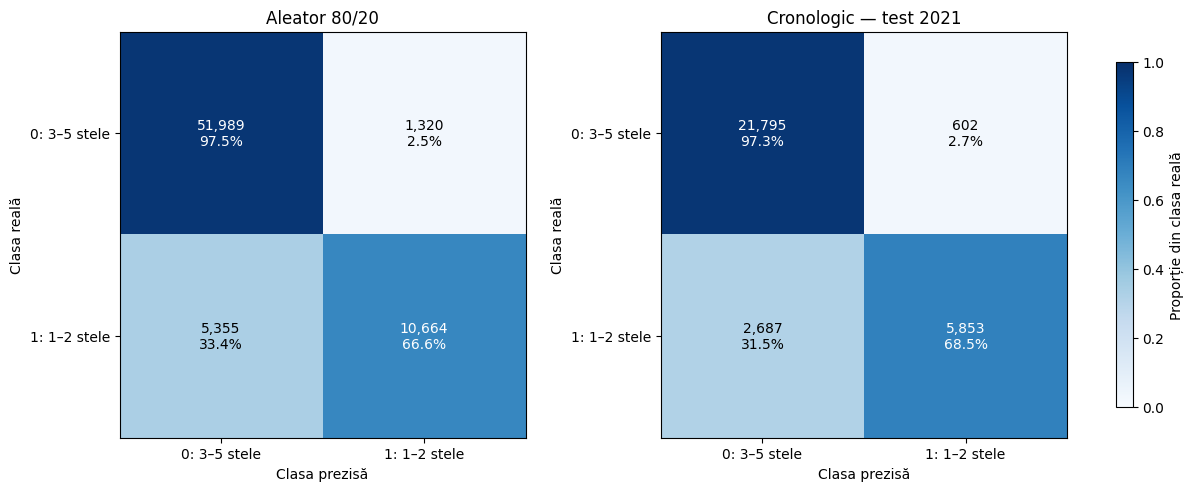

In [0]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.8),
    constrained_layout=True,
)

for ax, result in zip(axes, evaluation_results):
    counts = np.array([
        [result["tn"], result["fp"]],
        [result["fn"], result["tp"]],
    ])

    row_totals = counts.sum(axis=1, keepdims=True)

    proportions = np.divide(
        counts,
        row_totals,
        out=np.zeros_like(counts, dtype=float),
        where=row_totals != 0,
    )

    image = ax.imshow(
        proportions,
        cmap="Blues",
        vmin=0,
        vmax=1,
    )

    for row in range(2):
        for column in range(2):
            ax.text(
                column,
                row,
                f"{counts[row, column]:,}\n"
                f"{proportions[row, column]:.1%}",
                ha="center",
                va="center",
                color=(
                    "white"
                    if proportions[row, column] > 0.5
                    else "black"
                ),
            )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["0: 3–5 stele", "1: 1–2 stele"])
    ax.set_yticklabels(["0: 3–5 stele", "1: 1–2 stele"])
    ax.set_xlabel("Clasa prezisă")
    ax.set_ylabel("Clasa reală")
    ax.set_title(result["experiment"])

fig.colorbar(
    image,
    ax=axes,
    label="Proporție din clasa reală",
    shrink=0.85,
)

plt.show()

### 3.7. Interpretarea rezultatelor

Modelele au fost evaluate pe seturi separate de antrenare, folosind
pragul de clasificare 0.5.

| Indicator | Aleator 80/20 | Cronologic — test 2021 |
|---|---:|---:|
| Recenzii în test | 69.328 | 30.937 |
| Ponderea clasei de rating scăzut | 23,11% | 27,60% |
| Acuratețea reperului majoritar | 76,89% | 72,40% |
| Accuracy | 90,37% | 89,37% |
| Precision — clasa 1 | 88,99% | 90,67% |
| Recall — clasa 1 | 66,57% | 68,54% |
| F1 — clasa 1 | 76,16% | 78,07% |
| ROC-AUC | 0,9612 | 0,9692 |
| PR-AUC | 0,8830 | 0,9152 |

Ambele experimente depășesc acuratețea unui clasificator care prezice
întotdeauna clasa majoritară. Acest reper ar avea însă recall zero
pentru recenziile cu rating scăzut.

#### Precizia semnalărilor și recenziile omise

În experimentul aleator, modelul identifică corect 10.664 de recenzii
cu rating scăzut și produce 1.320 de semnalări incorecte.
Alte 5.355 de recenzii cu rating scăzut nu sunt identificate.

În experimentul cronologic, modelul identifică corect 5.853 de recenzii
cu rating scăzut și produce 602 semnalări incorecte.
Alte 2.687 de recenzii cu rating scăzut nu sunt identificate.

Precision este ridicată în ambele scenarii, dar recall este mai redus.
Prin urmare, modelul este mai potrivit pentru alcătuirea unei liste
prioritare de recenzii de analizat decât pentru detectarea exhaustivă
a tuturor recenziilor cu rating scăzut.

#### Compararea scenariilor

Experimentul cronologic are accuracy mai mică, dar valori mai mari
pentru precision, recall, F1, ROC-AUC și PR-AUC.

Aceste rezultate nu demonstrează că împărțirea cronologică produce
în general un model superior. Experimentele folosesc seturi de
antrenare și test diferite, iar clasa de rating scăzut este mai
frecventă în testul cronologic. În particular, PR-AUC depinde și
de proporția clasei pozitive.

Rezultatele nu indică o degradare a indicatorilor de identificare
a clasei pozitive în scenariul cronologic analizat. Totuși, un singur
an de test nu garantează aceeași performanță în alte perioade.

#### Utilitatea și limitele predicțiilor

Predicțiile pot sprijini:
- prioritizarea recenziilor care necesită analiză;
- monitorizarea ponderii recenziilor estimate ca având rating scăzut,
  pe perioade și categorii de afaceri.

Modelul estimează o clasă derivată din rating, nu identifică automat
cauza nemulțumirii și nu măsoară direct calitatea unei afaceri.
Clasa `0.0` include și recenziile de 3 stele.

Eliminarea cuvintelor uzuale, reprezentarea prin hashing și lipsa
modelării explicite a contextului pot limita interpretarea negațiilor,
a sarcasmului și a expresiilor complexe. Probabilitățile estimate
nu au fost evaluate din perspectiva calibrării.

Separarea folosită nu impune utilizatori sau afaceri distincte între
antrenare și test. Rezultatele nu trebuie interpretate ca o evaluare
dedicată exclusiv utilizatorilor sau afacerilor complet noi.


### 3.8. Modelul ales pentru fluxul final

Pentru fluxul de predicții și dashboard este ales pipeline-ul
cronologic, antrenat pe recenziile din perioada 2005–2019.

Alegerea reflectă scenariul de utilizare: aplicarea unui model
antrenat pe date istorice asupra recenziilor ulterioare.
Experimentul aleator rămâne un scenariu complementar de evaluare.

Se păstrează configurația inițială și pragul 0.5. Nu au fost efectuate
ajustări de parametri sau de prag pe setul de test din 2021.
Setul de validare din 2020 nu a fost utilizat pentru ajustări în
această rundă.

Pentru dashboard se vor utiliza predicțiile pe setul cronologic
de test din 2021, astfel încât indicatorii de performanță să reflecte
date care nu au participat la antrenare.

Predicțiile reprezintă o simulare retrospectivă pe date istorice,
nu un flux de recenzii colectate în timp real.


### 3.9. Salvarea și reutilizarea pipeline-ului

Pipeline-ul cronologic este salvat integral, incluzând etapele de
prelucrare a textului, ponderile IDF și clasificatorul antrenat.

Salvarea întregului pipeline permite aplicarea acelorași transformări
asupra datelor noi, fără recalcularea IDF sau reantrenarea modelului.

Artefactul este păstrat într-un Unity Catalog Volume dedicat modelelor.
Acesta este un artefact Spark ML salvat în fișiere, nu un model
înregistrat în Model Registry.

După salvare, pipeline-ul este reîncărcat și aplicat setului de test
din 2021. Rezultatele sunt comparate cu predicțiile modelului din memorie.

In [0]:
from pyspark.ml import PipelineModel

spark.sql("""
    CREATE VOLUME IF NOT EXISTS workspace.big_data_lab2.model_artifacts
""")

MODEL_PATH = (
    "/Volumes/workspace/big_data_lab2/model_artifacts/"
    "review_low_rating_lr_chrono_v1"
)

chrono_model.write().overwrite().save(MODEL_PATH)

loaded_model = PipelineModel.load(MODEL_PATH)

print("Pipeline salvat și reîncărcat.")
print("Cale:", MODEL_PATH)
print("Număr de etape:", len(loaded_model.stages))

assert len(loaded_model.stages) == 5

Pipeline salvat și reîncărcat.
Cale: /Volumes/workspace/big_data_lab2/model_artifacts/review_low_rating_lr_chrono_v1
Număr de etape: 5


In [0]:
reloaded_predictions = predict_reviews(loaded_model, chrono_test)

original_check = chrono_predictions.select(
    "review_id",
    F.col("prediction").alias("original_prediction"),
    F.col("low_rating_probability").alias("original_probability"),
)

reloaded_check = reloaded_predictions.select(
    "review_id",
    F.col("prediction").alias("reloaded_prediction"),
    F.col("low_rating_probability").alias("reloaded_probability"),
)

comparison = original_check.join(
    reloaded_check,
    on="review_id",
    how="full",
)

comparison_summary = comparison.agg(
    F.count("*").alias("n_compared"),
    F.sum(
        F.when(
            F.col("original_prediction").isNull()
            | F.col("reloaded_prediction").isNull(),
            1,
        ).otherwise(0)
    ).alias("missing_predictions"),
    F.sum(
        F.when(
            F.col("original_prediction") != F.col("reloaded_prediction"),
            1,
        ).otherwise(0)
    ).alias("different_predictions"),
    F.max(
        F.abs(
            F.col("original_probability")
            - F.col("reloaded_probability")
        )
    ).alias("max_probability_difference"),
).first().asDict()

for key, value in comparison_summary.items():
    print(f"{key}: {value}")

assert comparison_summary["n_compared"] == 30_937
assert comparison_summary["missing_predictions"] == 0
assert comparison_summary["different_predictions"] == 0
assert comparison_summary["max_probability_difference"] <= 1e-12

print("\nVerificarea reutilizării modelului a trecut.")

n_compared: 30937
missing_predictions: 0
different_predictions: 0
max_probability_difference: 0.0

Verificarea reutilizării modelului a trecut.


### 3.10. Salvarea predicțiilor în Delta Lake

Predicțiile generate cu pipeline-ul reîncărcat sunt salvate în tabelul
`workspace.big_data_lab2.review_predictions`.

Tabelul conține o înregistrare pentru fiecare recenzie din setul de
test cronologic din 2021, cu:
- identificatorul recenziei și al afacerii;
- data recenziei, anul și luna;
- numele afacerii, orașul, statul și categoria principală;
- ratingul și eticheta reală;
- clasa prezisă și probabilitatea estimată pentru rating scăzut;
- indicatori pentru clasificări corecte, semnalări false și cazuri omise;
- identificarea modelului, scenariul de evaluare și momentul procesării.

Ratingul real și atributele afacerii sunt adăugate pentru analiză,
după generarea predicțiilor. Ele nu sunt utilizate drept predictori.

Textul integral și vectorii intermediari nu sunt păstrați în acest
tabel, pentru a reduce volumul de date transferat către dashboard.

În această etapă tabelul este salvat fără partiționare explicită.
Organizarea în partiții și demonstrațiile de recuperare vor fi
abordate separat, în secțiunea de fiabilitate.

Modul `overwrite` înlocuiește rezultatul existent la reluarea celulei.
Această operație nu constituie încă demonstrația de recuperare
incrementală fără pierderi sau duplicate.

In [0]:
PREDICTIONS_TABLE = "workspace.big_data_lab2.review_predictions"

review_context = (
    spark.table(TABLE_NAME)
    .filter(F.col("year") == 2021)
    .select(
        "review_id",
        "business_id",
        "stars",
        "month",
        F.col("name").alias("business_name"),
        "city",
        "state",
        "main_category",
    )
)

dashboard_predictions = (
    reloaded_predictions
    .drop("rawPrediction")
    .join(
        review_context,
        on="review_id",
        how="inner",
    )
    .withColumn(
        "is_correct",
        (F.col("prediction") == F.col("label")).cast("int"),
    )
    .withColumn(
        "is_false_positive",
        (
            (F.col("prediction") == 1.0)
            & (F.col("label") == 0.0)
        ).cast("int"),
    )
    .withColumn(
        "is_false_negative",
        (
            (F.col("prediction") == 0.0)
            & (F.col("label") == 1.0)
        ).cast("int"),
    )
    .withColumn(
        "model_id",
        F.lit("review_low_rating_lr_chrono_v1"),
    )
    .withColumn("evaluation_split", F.lit("chronological_test_2021"))
    .withColumn("prediction_threshold", F.lit(0.5))
    .withColumn("processed_at", F.current_timestamp())
    .select(
        "review_id",
        "business_id",
        "business_name",
        "date",
        "year",
        "month",
        "city",
        "state",
        "main_category",
        "stars",
        "label",
        "prediction",
        "low_rating_probability",
        "is_correct",
        "is_false_positive",
        "is_false_negative",
        "model_id",
        "evaluation_split",
        "prediction_threshold",
        "processed_at",
    )
)

before_write = dashboard_predictions.agg(
    F.count("*").alias("n_reviews"),
    F.countDistinct("review_id").alias("n_distinct_review_ids"),
).first().asDict()

assert before_write["n_reviews"] == 30_937
assert before_write["n_distinct_review_ids"] == 30_937

(
    dashboard_predictions.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(PREDICTIONS_TABLE)
)

print("Tabel de predicții salvat:", PREDICTIONS_TABLE)

Tabel de predicții salvat: workspace.big_data_lab2.review_predictions


In [0]:
saved_predictions = spark.table(PREDICTIONS_TABLE)

saved_summary = saved_predictions.agg(
    F.count("*").alias("n_reviews"),
    F.countDistinct("review_id").alias("n_distinct_review_ids"),
    F.sum("is_correct").alias("n_correct"),
    F.sum("is_false_positive").alias("fp"),
    F.sum("is_false_negative").alias("fn"),
    F.sum(
        F.when(
            (F.col("label") == 1.0)
            & (F.col("prediction") == 1.0),
            1,
        ).otherwise(0)
    ).alias("tp"),
    F.sum(
        F.when(
            F.col("low_rating_probability").isNull()
            | F.isnan("low_rating_probability")
            | (F.col("low_rating_probability") < 0)
            | (F.col("low_rating_probability") > 1),
            1,
        ).otherwise(0)
    ).alias("invalid_probability"),
).first().asDict()

for key, value in saved_summary.items():
    print(f"{key}: {value}")

assert saved_summary["n_reviews"] == 30_937
assert saved_summary["n_distinct_review_ids"] == 30_937
assert saved_summary["n_correct"] == 21_795 + 5_853
assert saved_summary["fp"] == 602
assert saved_summary["fn"] == 2_687
assert saved_summary["tp"] == 5_853
assert saved_summary["invalid_probability"] == 0

saved_format = (
    spark.sql(f"DESCRIBE DETAIL {PREDICTIONS_TABLE}")
    .select("format")
    .first()["format"]
)

assert saved_format == "delta"

print("\nFormat:", saved_format)
print("Verificările tabelului de predicții au trecut.")

display(
    saved_predictions.select(
        "review_id",
        "business_name",
        "date",
        "label",
        "prediction",
        "low_rating_probability",
    ).limit(10)
)

n_reviews: 30937
n_distinct_review_ids: 30937
n_correct: 27648
fp: 602
fn: 2687
tp: 5853
invalid_probability: 0

Format: delta
Verificările tabelului de predicții au trecut.


review_id,business_name,date,label,prediction,low_rating_probability
zFpBARE-azslyeD6o2EA5w,Mr Ed's Oyster Bar - Bienville,2021-08-07T10:11:25.000Z,0.0,0.0,0.10309001665948903
bCwJs861tVGOyEXI33tzkg,Springhill Suites by Marriott Tampa North/I-75 Tampa Palms,2021-11-19T00:12:18.000Z,1.0,1.0,0.9813565382797045
qOMpFsqY3CgEIodi_qI3bw,Mister Car Wash,2021-08-29T15:54:37.000Z,1.0,1.0,0.7990469719045884
ec5oUafL10bPuJWIHZPDyg,Old Northeast Tavern,2021-04-04T18:11:33.000Z,0.0,0.0,0.044200276666217286
R8MDARJRHHDi0kAn-krtzQ,Groupers On The Gulf,2021-11-02T00:11:15.000Z,1.0,0.0,0.47784884925549087
NeRzxZruNjiNk6UjAUPJeQ,Butchertown Hall,2021-02-19T15:50:42.000Z,0.0,0.0,0.11883080107176014
uVLRkY2mmBVxsOH5YZJMIA,E3 Chophouse,2021-09-27T03:28:43.000Z,0.0,0.0,1.1090297255400561E-4
f254Z0Ckp5C77P5psWdS2A,Zimmer's Seafood,2021-02-09T02:05:21.000Z,0.0,0.0,0.006558735420520767
loI8z06kO0HTFyusYZDC1A,Martin Ross Security,2021-05-15T06:45:13.000Z,1.0,1.0,0.7931197584816935
_5yO6Ufv3Pk-anyEUnQGvA,Overland Armament,2021-01-20T00:20:35.000Z,0.0,0.0,0.1503572022427473


### 3.11. Verificarea reutilizării modelului și a predicțiilor persistate

Pipeline-ul cronologic a fost salvat și reîncărcat din volumul
`workspace.big_data_lab2.model_artifacts`.

Compararea predicțiilor modelului reîncărcat cu cele ale modelului
din memorie a produs următoarele rezultate:

| Indicator | Rezultat |
|---|---:|
| Recenzii comparate | 30.937 |
| Predicții lipsă | 0 |
| Clase prezise diferit | 0 |
| Diferența maximă absolută între probabilități | 0,0 |

Rezultatul confirmă că pipeline-ul salvat poate fi reutilizat pentru
inferență și reproduce predicțiile inițiale pe setul verificat,
fără reantrenare.

Predicțiile au fost persistate în tabelul Delta
`workspace.big_data_lab2.review_predictions`, împreună cu atributele
temporale și informațiile despre afaceri necesare dashboardului.

| Indicator | Rezultat |
|---|---:|
| Format | Delta |
| Recenzii persistate | 30.937 |
| Identificatori distincți | 30.937 |
| Clasificări corecte | 27.648 |
| Semnalări false — FP | 602 |
| Recenzii cu rating scăzut omise — FN | 2.687 |
| Recenzii cu rating scăzut identificate — TP | 5.853 |
| Probabilități nule, NaN sau în afara intervalului [0, 1] | 0 |

Numărul de recenzii și indicatorii de clasificare coincid cu
rezultatele evaluării cronologice. Tabelul persistat poate fi
utilizat în etapa de organizare fiabilă a fluxului și în dashboard.

Această verificare demonstrează persistența și reutilizarea
modelului, precum și integritatea indicatorilor verificați după
salvarea predicțiilor. Nu reprezintă încă demonstrația recuperării
după întreruperea procesării.


## 4. Organizare, fiabilitate și monitorizare

### 4.1. Partiționarea predicțiilor

Predicțiile setului de test din 2021 sunt organizate într-un tabel
Delta partiționat după coloana `month`.

Alegerea lunii permite demonstrarea partiționării pentru interogări
temporale, de exemplu selectarea predicțiilor dintr-o anumită lună.
Nu se partiționează după `year`, deoarece toate înregistrările
din acest tabel aparțin anului 2021.

Partiționarea poate permite omiterea partițiilor care nu corespund
filtrului unei interogări. Pentru acest subset mic, însă, crearea
mai multor partiții poate introduce costuri suplimentare și fișiere
mici. Alegerea are un scop demonstrativ și nu reprezintă o afirmație
că aceasta este organizarea optimă pentru volumul analizat.

Tabelul inițial de predicții este păstrat nemodificat ca reper.

#### Partiționare și sharding

Partiționarea unui tabel Delta organizează datele în funcție de
valorile unor coloane. Nu este echivalentă cu administrarea unor
sharduri pe servere independente.

Sharding-ul presupune distribuirea unor subseturi de date între
noduri sau instanțe de stocare. În acest laborator se demonstrează
partiționarea tabelului, nu configurarea unei infrastructuri de sharding.

In [0]:
from pyspark.sql import functions as F

SOURCE_PREDICTIONS_TABLE = "workspace.big_data_lab2.review_predictions"

PARTITIONED_TABLE = (
    "workspace.big_data_lab2.review_predictions_partitioned"
)

BACKUP_TABLE = (
    "workspace.big_data_lab2.review_predictions_backup"
)

source_predictions = spark.table(SOURCE_PREDICTIONS_TABLE)

# Confirmăm ipotezele utilizate la alegerea partiționării.
source_checks = source_predictions.agg(
    F.count("*").alias("n_reviews"),
    F.countDistinct("review_id").alias("n_distinct_review_ids"),
    F.sum(
        F.when(
            F.col("year").isNull() | (F.col("year") != 2021),
            1,
        ).otherwise(0)
    ).alias("invalid_year"),
    F.sum(
        F.when(
            F.col("month").isNull()
            | (~F.col("month").between(1, 12))
            | (F.col("month") != F.month("date")),
            1,
        ).otherwise(0)
    ).alias("invalid_month"),
).first().asDict()

assert source_checks["n_reviews"] == 30_937
assert source_checks["n_distinct_review_ids"] == 30_937
assert source_checks["invalid_year"] == 0
assert source_checks["invalid_month"] == 0

(
    source_predictions.write
    .format("delta")
    .mode("overwrite")
    .partitionBy("month")
    .saveAsTable(PARTITIONED_TABLE)
)

partition_details = spark.sql(f"DESCRIBE DETAIL {PARTITIONED_TABLE}")

details = partition_details.select(
    "format", "partitionColumns"
).first()

assert details["format"] == "delta"
assert list(details["partitionColumns"]) == ["month"]

print("Tabel creat:", PARTITIONED_TABLE)
print("Coloane de partiționare:", details["partitionColumns"])

display(
    partition_details.select(
        "name", "format", "partitionColumns", "numFiles", "sizeInBytes"
    )
)

display(
    spark.table(PARTITIONED_TABLE)
    .groupBy("year", "month")
    .count()
    .orderBy("year", "month")
)

Tabel creat: workspace.big_data_lab2.review_predictions_partitioned
Coloane de partiționare: ['month']


name,format,partitionColumns,numFiles,sizeInBytes
workspace.big_data_lab2.review_predictions_partitioned,delta,List(month),12,2021050


year,month,count
2021,1,2295
2021,2,2123
2021,3,2736
2021,4,2685
2021,5,2876
2021,6,2845
2021,7,3011
2021,8,2762
2021,9,2335
2021,10,2484


### 4.2. Crearea unei copii separate

Se creează un al doilea tabel Delta prin citirea unei versiuni fixe
a tabelului partiționat și scrierea datelor într-un tabel separat.

Copierea materializează datele în fișierele tabelului de backup.
Nu se utilizează un view sau un shallow clone care ar depinde
de fișierele de date ale sursei.

Versiunea sursă folosită pentru copiere este afișată în notebook.
După scriere se verifică:
- formatul Delta;
- existența unor identificatori Delta diferiți pentru sursă și backup;
- numărul de rânduri și unicitatea identificatorilor;
- egalitatea conținutului, în ambele sensuri.

În mediul utilizat, `DESCRIBE DETAIL` returnează un șir gol pentru
locațiile ambelor tabele. Prin urmare, căile fizice nu pot fi comparate
prin aceste metadate.

Identificatorii Delta diferiți confirmă identitatea distinctă a
tabelelor. Copia este creată printr-o scriere separată a datelor,
iar egalitatea conținutului este verificată în ambele sensuri.

Copia este un instantaneu la momentul operației. Modificările ulterioare
ale sursei nu sunt propagate automat.

#### Backup și replicare automată

Backupul păstrează o copie separată pentru recuperare.
Replicarea automată propagă modificările între copii conform
mecanismelor infrastructurii și nu este implementată aici.

Ambele tabele se află în același mediu Databricks. Prin urmare,
demonstrația nu oferă protecție verificată împotriva pierderii
întregului workspace sau a infrastructurii de stocare.

Reluarea celulei de backup înlocuiește copia anterioară; nu construiește
o arhivă cu mai multe generații de backup.

In [0]:
# Identificăm ultima versiune a tabelului sursă.
backup_source_version = (
    spark.sql(f"DESCRIBE HISTORY {PARTITIONED_TABLE}")
    .agg(F.max("version").alias("version"))
    .first()["version"]
)

# Citim explicit acea versiune pentru un snapshot bine definit.
backup_source_snapshot = (
    spark.read
    .option("versionAsOf", backup_source_version)
    .table(PARTITIONED_TABLE)
)

(
    backup_source_snapshot.write
    .format("delta")
    .mode("overwrite")
    .partitionBy("month")
    .saveAsTable(BACKUP_TABLE)
)

print("Versiunea sursă copiată:", backup_source_version)
print("Tabel backup:", BACKUP_TABLE)

Versiunea sursă copiată: 0
Tabel backup: workspace.big_data_lab2.review_predictions_backup


In [0]:
bbackup_df = spark.table(BACKUP_TABLE)

backup_details = (
    spark.sql(f"DESCRIBE DETAIL {BACKUP_TABLE}")
    .select("id", "format", "location", "partitionColumns")
    .first()
)

source_details = (
    spark.sql(f"DESCRIBE DETAIL {PARTITIONED_TABLE}")
    .select("id", "format", "location", "partitionColumns")
    .first()
)

backup_checks = backup_df.agg(
    F.count("*").alias("n_reviews"),
    F.countDistinct("review_id").alias("n_distinct_review_ids"),
).first().asDict()

assert backup_details["format"] == "delta"
assert source_details["format"] == "delta"

assert source_details["id"]
assert backup_details["id"]
assert backup_details["id"] != source_details["id"]

assert backup_checks["n_reviews"] == 30_937
assert backup_checks["n_distinct_review_ids"] == 30_937

# Comparăm locațiile numai dacă sunt expuse pentru ambele tabele.
locations_available = bool(
    source_details["location"] and backup_details["location"]
)

if locations_available:
    assert backup_details["location"] != source_details["location"]

assert backup_source_snapshot.schema == backup_df.schema

comparison_columns = backup_source_snapshot.columns

source_only_exists = (
    backup_source_snapshot.select(*comparison_columns)
    .exceptAll(backup_df.select(*comparison_columns))
    .limit(1)
    .count()
)

backup_only_exists = (
    backup_df.select(*comparison_columns)
    .exceptAll(backup_source_snapshot.select(*comparison_columns))
    .limit(1)
    .count()
)

assert source_only_exists == 0
assert backup_only_exists == 0

print("Format backup:", backup_details["format"])
print(
    "Identificatori Delta diferiți:",
    backup_details["id"] != source_details["id"],
)
print("Locații disponibile pentru comparație:", locations_available)
print("Rânduri în backup:", backup_checks["n_reviews"])
print(
    "Identificatori distincți:",
    backup_checks["n_distinct_review_ids"],
)
print(
    "Conținut identic cu versiunea sursă:",
    source_only_exists == 0 and backup_only_exists == 0,
)
print("Verificările copiei de siguranță au trecut.")

Format backup: delta
Identificatori Delta diferiți: True
Locații disponibile pentru comparație: False
Rânduri în backup: 30937
Identificatori distincți: 30937
Conținut identic cu versiunea sursă: True
Verificările copiei de siguranță au trecut.


In [0]:
display(
    spark.table(PARTITIONED_TABLE)
    .filter(F.col("month") == 6)
    .agg(
        F.count("*").alias("n_reviews"),
        F.sum("prediction").cast("long").alias("n_predicted_low_rating"),
        F.round(
            100 * F.avg("prediction"), 2
        ).alias("predicted_low_rating_pct"),
    )
)

# Planul permite inspectarea filtrului aplicat la citire.
spark.table(PARTITIONED_TABLE).filter(
    F.col("month") == 6
).explain(mode="formatted")

n_reviews,n_predicted_low_rating,predicted_low_rating_pct
2845,568,19.96


== Physical Plan ==
PhotonResultStage (4)
+- PhotonColumnarToRow (3)
   +- PhotonProject (2)
      +- PhotonScan parquet workspace.big_data_lab2.review_predictions_partitioned (1)


(1) PhotonScan parquet workspace.big_data_lab2.review_predictions_partitioned
Output [20]: [review_id#20826, business_id#20827, business_name#20828, date#20829, year#20830, city#20832, state#20833, main_category#20834, stars#20835, label#20836, prediction#20837, low_rating_probability#20838, is_correct#20839, is_false_positive#20840, is_false_negative#20841, model_id#20842, evaluation_split#20843, prediction_threshold#20844, processed_at#20845, month#20831]
Location: PreparedDeltaFileIndex [s3://dbstorage-prod-s5motcmlt2/uc/e4f6ac69-8603-42bf-9845-5dedb98f2880/d8f65e78-b4fd-4c13-93a0-763d5dd3b259/__unitystorage/catalogs/bb8d8f13-2643-4ed7-ab4d-054d2ee37725/tables/4f713b19-723f-4c76-8d22-6e7dbc823bdc]
PartitionFilters: [isnotnull(month#20831), (month#20831 = 6)]
ReadSchema: struct<review_id:string,business_i

### 4.3. Simularea întreruperii și reluarea procesării

Demonstrația utilizează un tabel separat, fără modificarea tabelului
de predicții validat sau a backupului.

Predicțiile deja calculate sunt procesate în loturi lunare.
Fiecare lot este introdus printr-o operație Delta MERGE, folosind
`review_id` drept cheie. Recenziile existente sunt ignorate,
iar cele absente sunt inserate.

Se simulează o eroare în aplicație imediat după confirmarea scrierii
primului lot, înainte ca aplicația să raporteze finalizarea acestuia.
Acesta este un caz în care, la reluare, aplicația poate retrimite
un lot care a fost deja salvat.

La reluare se retrimit toate loturile. Operația MERGE trebuie să evite
duplicarea recenziilor deja existente și să insereze loturile rămase.

La final se verifică:
- numărul total de rânduri;
- unicitatea identificatorilor;
- egalitatea integrală cu instantaneul sursă;
- stabilitatea rezultatului după o nouă retrimitere a tuturor loturilor.

Demonstrația verifică reluarea etapei de persistare a predicțiilor.
Nu simulează oprirea clusterului, o defecțiune fizică de stocare sau
r

In [0]:
from delta.tables import DeltaTable
from time import perf_counter
from pyspark.sql import functions as F

RECOVERY_TABLE = "workspace.big_data_lab2.review_predictions_recovery_demo"

# Folosim instantaneul fix deja utilizat pentru backup.
recovery_source = backup_source_snapshot

recovery_months = [
    row["month"]
    for row in (
        recovery_source.select("month")
        .distinct()
        .orderBy("month")
        .collect()
    )
]

assert recovery_months

# Resetăm exclusiv destinația demonstrației.
(
    recovery_source.limit(0).write
    .format("delta")
    .mode("overwrite")
    .partitionBy("month")
    .saveAsTable(RECOVERY_TABLE)
)

recovery_log = []

def merge_prediction_month(month):
    batch = recovery_source.filter(F.col("month") == month)

    (
        DeltaTable.forName(spark, RECOVERY_TABLE)
        .alias("target")
        .merge(
            batch.alias("source"),
            "target.review_id = source.review_id",
        )
        .whenNotMatchedInsertAll()
        .execute()
    )

def process_prediction_month(month, simulate_failure=False):
    started = perf_counter()
    status = "success"
    error_message = ""

    try:
        merge_prediction_month(month)

        if simulate_failure:
            raise RuntimeError(
                "Întrerupere simulată după commit-ul lotului."
            )

    except Exception as error:
        status = "error"
        error_message = str(error)
        raise

    finally:
        recovery_log.append({
            "month": int(month),
            "status": status,
            "duration_seconds": float(perf_counter() - started),
            "error_message": error_message,
        })

print("Tabel de demonstrație pregătit:", RECOVERY_TABLE)
print("Luni de procesat:", recovery_months)

Tabel de demonstrație pregătit: workspace.big_data_lab2.review_predictions_recovery_demo
Luni de procesat: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [0]:
first_month = recovery_months[0]

try:
    process_prediction_month(
        first_month,
        simulate_failure=True,
    )
except RuntimeError as error:
    if str(error) != "Întrerupere simulată după commit-ul lotului.":
        raise
    print("Eroare intenționată capturată:", error)

expected_first_batch = (
    recovery_source
    .filter(F.col("month") == first_month)
    .count()
)

rows_after_failure = spark.table(RECOVERY_TABLE).count()
source_total = recovery_source.count()

assert rows_after_failure == expected_first_batch
assert 0 < rows_after_failure < source_total

print("Luna procesată:", first_month)
print("Rânduri persistate după întrerupere:", rows_after_failure)
print("Total așteptat la final:", source_total)

Eroare intenționată capturată: Întrerupere simulată după commit-ul lotului.
Luna procesată: 1
Rânduri persistate după întrerupere: 2295
Total așteptat la final: 30937


In [0]:
for month in recovery_months:
    process_prediction_month(month)
    print(f"Luna {month}: procesată")

print("Reluarea tuturor loturilor s-a încheiat.")

Luna 1: procesată
Luna 2: procesată
Luna 3: procesată
Luna 4: procesată
Luna 5: procesată
Luna 6: procesată
Luna 7: procesată
Luna 8: procesată
Luna 9: procesată
Luna 10: procesată
Luna 11: procesată
Luna 12: procesată
Reluarea tuturor loturilor s-a încheiat.


In [0]:
def verify_recovery():
    recovered = spark.table(RECOVERY_TABLE)

    counts = recovered.agg(
        F.count("*").alias("n_reviews"),
        F.countDistinct("review_id").alias("n_distinct_review_ids"),
    ).first().asDict()

    assert counts["n_reviews"] == source_total == 30_937
    assert counts["n_distinct_review_ids"] == source_total

    columns = recovery_source.columns

    assert (
        recovery_source.select(*columns)
        .exceptAll(recovered.select(*columns))
        .limit(1)
        .count()
        == 0
    )

    assert (
        recovered.select(*columns)
        .exceptAll(recovery_source.select(*columns))
        .limit(1)
        .count()
        == 0
    )

    return counts

after_resume = verify_recovery()
print("După reluare:", after_resume)

# Retrimitere integrală suplimentară.
for month in recovery_months:
    process_prediction_month(month)

after_replay = verify_recovery()
print("După retrimitere integrală:", after_replay)

print("Conținut identic cu sursa: True")
print("Verificările recuperării și idempotentei au trecut.")

După reluare: {'n_reviews': 30937, 'n_distinct_review_ids': 30937}
După retrimitere integrală: {'n_reviews': 30937, 'n_distinct_review_ids': 30937}
Conținut identic cu sursa: True
Verificările recuperării și idempotentei au trecut.


### 4.4. Monitorizarea execuției

Pentru fiecare încercare de procesare se înregistrează luna, starea,
durata și mesajul erorii. Jurnalul aplicației permite identificarea
încercării întrerupte și a reluărilor reușite.

Jurnalul este păstrat în memoria sesiunii pentru această demonstrație;
nu este un sistem durabil de monitorizare și s-ar pierde la resetarea
sesiunii.

Istoricul Delta este inspectat separat pentru a observa operațiile
efectuate asupra tabelului. O eroare raportată de aplicație după commit
nu implică anularea tranzacției deja confirmate.

Duratele pot indica loturi care necesită investigații suplimentare,
dar nu identifică singure cauza unei probleme de performanță.
Pentru aceasta se inspectează și detaliile execuției din interfața
Databricks, inclusiv planul și statisticile disponibile.

In [0]:
display(
    spark.createDataFrame([
        {"attempt": index, **entry}
        for index, entry in enumerate(recovery_log, start=1)
    ]).orderBy("attempt")
)

display(
    spark.sql(f"DESCRIBE HISTORY {RECOVERY_TABLE}")
    .select(
        "version",
        "timestamp",
        "operation",
        "operationMetrics",
    )
    .orderBy(F.desc("version"))
)

attempt,duration_seconds,error_message,month,status
1,4.222915940999883,Întrerupere simulată după commit-ul lotului.,1,error
2,2.774162250999325,,1,success
3,3.190512404999936,,2,success
4,3.1201965339996605,,3,success
5,3.0055646569999226,,4,success
6,3.2218361020004522,,5,success
7,3.7790697410000575,,6,success
8,3.249587049999718,,7,success
9,3.3150739980001163,,8,success
10,4.455924973000037,,9,success


version,timestamp,operation,operationMetrics
25,2026-10-27T10:55:14.000Z,MERGE,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 0, numTargetBytesAdded -> 0, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 0, numTargetRowsMatchedUpdated -> 0, executionTimeMs -> 1748, materializeSourceTimeMs -> 12, numTargetRowsInserted -> 0, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 0, numTargetRowsUpdated -> 0, numOutputRows -> 0, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 2480, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1697)"
24,2026-10-27T10:55:11.000Z,MERGE,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 0, numTargetBytesAdded -> 0, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 0, numTargetRowsMatchedUpdated -> 0, executionTimeMs -> 1592, materializeSourceTimeMs -> 10, numTargetRowsInserted -> 0, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 0, numTargetRowsUpdated -> 0, numOutputRows -> 0, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 2305, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1553)"
23,2026-10-27T10:55:08.000Z,MERGE,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 0, numTargetBytesAdded -> 0, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 0, numTargetRowsMatchedUpdated -> 0, executionTimeMs -> 1599, materializeSourceTimeMs -> 10, numTargetRowsInserted -> 0, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 0, numTargetRowsUpdated -> 0, numOutputRows -> 0, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 2484, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1559)"
22,2026-10-27T10:55:05.000Z,MERGE,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 0, numTargetBytesAdded -> 0, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 0, numTargetRowsMatchedUpdated -> 0, executionTimeMs -> 1631, materializeSourceTimeMs -> 13, numTargetRowsInserted -> 0, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 0, numTargetRowsUpdated -> 0, numOutputRows -> 0, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 2335, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1587)"
21,2026-10-27T10:55:02.000Z,MERGE,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 0, numTargetBytesAdded -> 0, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 0, numTargetRowsMatchedUpdated -> 0, executionTimeMs -> 1698, materializeSourceTimeMs -> 9, numTargetRowsInserted -> 0, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 0, numTargetRowsUpdated -> 0, numOutputRows -> 0, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 2762, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1662)"
20,2026-10-27T10:54:59.000Z,MERGE,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 0, numTargetBytesAdded -> 0, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 0, numTargetRowsMatchedUpdated -> 0, executionTimeMs -> 1584, materializeSourceTimeMs -> 9, numTargetRowsInserted -> 0, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 0, numTargetRowsUpdated -> 0, numOutputRows -> 0, numTargetD

### 4.5. Rezultatele demonstrației de recuperare

Întreruperea a fost simulată după confirmarea tranzacției pentru
primul lot lunar, dar înainte ca aplicația să raporteze succesul.

După eroare, tabelul conținea cele 2.295 de recenzii din luna ianuarie.
Astfel, eroarea aplicației nu a anulat tranzacția Delta deja confirmată.

Procesarea a fost reluată prin retrimiterea tuturor loturilor lunare,
inclusiv a lotului deja salvat. Operația MERGE insert-only a folosit
`review_id` pentru a insera numai recenziile absente.

| Momentul verificării | Rânduri | Identificatori distincți |
|---|---:|---:|
| După întreruperea simulată | 2.295 | — |
| După reluarea tuturor loturilor | 30.937 | 30.937 |
| După o retrimitere integrală suplimentară | 30.937 | 30.937 |

După reluare și după retrimiterea suplimentară, comparațiile în ambele
sensuri prin `exceptAll` au confirmat egalitatea integrală cu
instantaneul sursă.

În condițiile demonstrației:
- nu s-au pierdut recenzii;
- nu s-au introdus identificatori duplicați;
- retrimiterea acelorași loturi nu a modificat rezultatul final.

Comportamentul idempotent rezultă din combinația dintre sursa cu
identificatori unici și MERGE insert-only pe `review_id`.
Simpla utilizare a formatului Delta nu elimină automat duplicatele
introduse prin orice tip de scriere.

#### Limitele demonstrației

Eroarea a fost injectată în aplicație după commit. Nu s-au simulat
oprirea clusterului, indisponibilitatea stocării sau scrieri concurente.

Demonstrația privește persistarea unor predicții deja calculate,
nu recuperarea antrenării sau a întregului proces de inferență.

Copia de siguranță a fost verificată separat; în această demonstrație
recuperarea s-a realizat prin retrimiterea loturilor, nu prin restaurarea
backupului.

Rezultatele sunt valabile pentru predicții nemodificate și cheia
`review_id`. Actualizarea predicțiilor pentru o nouă versiune a modelului
necesită o politică explicită de actualizare sau versionare.
